## Data sources and scope

Both files are Inside Airbnb detailed listings from 17 September 2026:

- [Barcelona](https://data.insideairbnb.com/spain/catalonia/barcelona/2026-09-17/data/listings.csv.gz), saved as `barcelona_listings.csv.gz`.
- [Madrid](https://data.insideairbnb.com/spain/comunidad-de-madrid/madrid/2026-09-17/data/listings.csv.gz), saved as `madrid_listings.csv.gz`.

We compare entire apartments and private rooms separately. We use at least one review in the previous 12 months as a proxy for recent activity. This excludes some new or unreviewed listings. Host IDs identify accounts managing listings on Airbnb, so the chart measures concentration among host accounts rather than legal property ownership. The simulation is a separate model in which ownership is explicitly tracked.

In [1]:
import pandas as pd
from math import ceil
from pathlib import Path

data_folder = Path('data')
if not data_folder.is_dir():
    data_folder = Path('../data')
reports_folder = data_folder.parent / 'reports'

columns = ['id', 'host_id', 'room_type', 'number_of_reviews_ltm']

barcelona = pd.read_csv(data_folder / 'barcelona_listings.csv.gz', usecols=columns, dtype={'id': 'Int64', 'host_id': 'Int64'})
madrid = pd.read_csv(data_folder / 'madrid_listings.csv.gz', usecols=columns, dtype={'id': 'Int64', 'host_id': 'Int64'})

In [2]:
def clean_listings(df, city):
    print(city, 'Initial listings:', len(df))
    before = len(df)
    df = df.dropna(subset=['id', 'host_id', 'room_type'])
    print('Missing values removed:', before - len(df))

    before = len(df)
    df = df.drop_duplicates(subset='id')
    print('Duplicates removed:', before - len(df))

    before = len(df)
    df = df[df['number_of_reviews_ltm'] > 0]
    print('Inactive listings removed:', before - len(df))

    before = len(df)
    room_types = ['Entire home/apt', 'Private room']
    df = df[df['room_type'].isin(room_types)].copy()
    print('Other room types removed:', before - len(df))
    df['city'] = city
    print(city, 'Clean listings:', len(df))
    return df

barcelona_clean = clean_listings(barcelona, 'Barcelona')
madrid_clean = clean_listings(madrid, 'Madrid')
listings = pd.concat([barcelona_clean, madrid_clean], ignore_index=True)

print(listings.groupby(['city', 'room_type']).size())

Barcelona Initial listings: 15236
Missing values removed: 0
Duplicates removed: 0
Inactive listings removed: 5298
Other room types removed: 156
Barcelona Clean listings: 9782
Madrid Initial listings: 23109
Missing values removed: 0
Duplicates removed: 0
Inactive listings removed: 6994
Other room types removed: 148
Madrid Clean listings: 15967
city       room_type      
Barcelona  Entire home/apt     7998
           Private room        1784
Madrid     Entire home/apt    12264
           Private room        3703
dtype: int64


In [3]:
# Rank hosts separately for each city and room type.
# Sort by number of listings in descending order.
# Break ties by host_id in ascending order.
# Round the top 10% up to the nearest whole host.

def top_host_count(number_of_hosts):
    return ceil(number_of_hosts * 0.10)

In [4]:
host_counts = listings.groupby(["city", "room_type", "host_id"]).size().reset_index(name="n_listings")

rows = []
for (city, room_type), group in host_counts.groupby(["city", "room_type"]):
    ranked = group.sort_values(["n_listings", "host_id"], ascending=[False, True])
    n_hosts = len(ranked)
    n_top = top_host_count(n_hosts)
    top_listings = ranked.head(n_top)["n_listings"].sum()
    total_listings = ranked["n_listings"].sum()
    share_pct = 100 * top_listings / total_listings
    rows.append({"city": city, "room_type": room_type, "n_hosts": n_hosts, "n_top": n_top, "top_listings": top_listings, "total_listings": total_listings, "share_pct": share_pct})

concentration = pd.DataFrame(rows)
concentration.round(2)

,city,room_type,n_hosts,n_top,top_listings,total_listings,share_pct
0,Barcelona,Entire home/apt,2313,232,4631,7998,57.90
1,Barcelona,Private room,656,66,627,1784,35.15
2,Madrid,Entire home/apt,4248,425,6787,12264,55.34
3,Madrid,Private room,1724,173,1462,3703,39.48


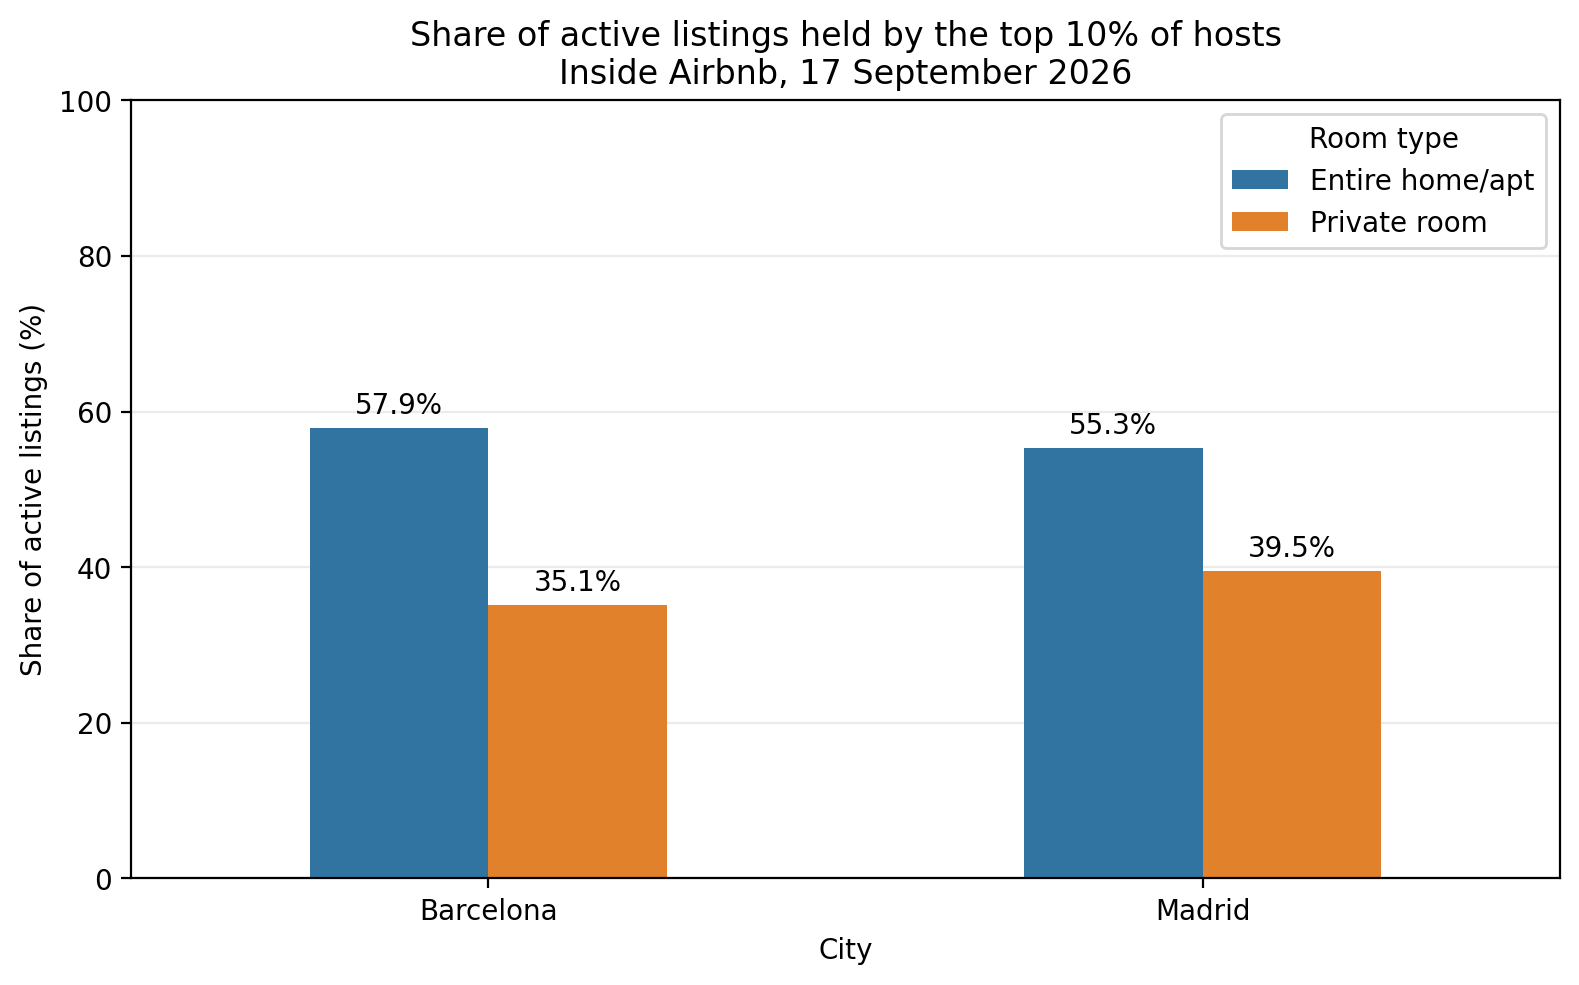

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

plot_data = concentration.pivot(index="city", columns="room_type", values="share_pct")
ax = plot_data.plot(kind="bar", figsize=(8, 5), rot=0, color=["#3274A1", "#E1812C"])

ax.set_title("Share of active listings held by the top 10% of hosts\nInside Airbnb, 17 September 2026")
ax.set_xlabel("City")
ax.set_ylabel("Share of active listings (%)")
ax.set_ylim(0, 100)
ax.legend(title="Room type")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(reports_folder / "graph3.png", dpi=200, bbox_inches="tight")
plt.close(ax.figure)
display(Image(filename=str(reports_folder / "graph3.png")))

### Interpretation

In both cities the top 10% of hosts account for a larger share of active listings among entire homes and apartments than among private rooms. The shares are 57.90% versus 35.15% in Barcelona and 55.34% versus 39.48% in Madrid.

Here, an active listing is one with at least one review in the previous 12 months.